# 01 · Data acquisition, cleaning and EDA
UCI Heart Disease (Cleveland subset, 303 patients, 13 clinical attributes + diagnosis).

The reusable logic lives in `src/heart/data.py` and `src/heart/eda.py`; this notebook runs it and records the findings.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 140)

## 1. Acquire
`scripts/download_data.py` tries the official UCI archive first and falls back to a public mirror of the same 303 records. `data/raw/SOURCE.txt` records which source was used and the file hash.

In [2]:
from heart.data import load_raw, download_raw
from heart.config import RAW_FILE
if not RAW_FILE.exists():
    download_raw()
print((RAW_FILE.parent / "SOURCE.txt").read_text())
raw = load_raw()
raw.head()

source: https://archive.ics.uci.edu/static/public/45/heart+disease.zip
rows: 303
sha256: 953d45066c221ee00cf8de72cfa4ab2086eb4e231fef6dda8fc3051b17840e61



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


## 2. Data quality checks

In [4]:
print("shape:", raw.shape)
print("duplicate rows:", raw.duplicated().sum())
print("missing values:\n", raw.isna().sum()[raw.isna().sum() > 0])
print("\ntarget 'num' levels:", raw["num"].value_counts().sort_index().to_dict())

shape: (303, 14)
duplicate rows: 0
missing values:
 ca      4
thal    2
dtype: int64

target 'num' levels: {0: 164, 1: 55, 2: 36, 3: 35, 4: 13}


Only **6 cells** are missing (`ca`: 4, `thal`: 2), about 2% of rows. Rather than dropping rows or imputing on the whole dataset (which would leak test-set statistics), cleaning keeps them as `NaN` and the model pipeline imputes them with statistics learned on the training folds only (median for numeric, most-frequent for categorical).

## 3. Clean
* coerce to numeric, drop duplicates and unlabelled rows
* out-of-range values and unknown category codes → `NaN`
* binarise the target: `num` 0 → 0 (no disease), 1–4 → 1 (disease)

In [5]:
from heart.data import build_clean_dataset
df = build_clean_dataset()
df.head()

,age,trestbps,chol,thalach,oldpeak,ca,sex,fbs,exang,cp,restecg,slope,thal,target
0,63.0,145.0,233.0,150.0,2.3,0.0,1.0,1.0,0.0,1.0,2.0,3.0,6.0,0
1,67.0,160.0,286.0,108.0,1.5,3.0,1.0,0.0,1.0,4.0,2.0,2.0,3.0,1
2,67.0,120.0,229.0,129.0,2.6,2.0,1.0,0.0,1.0,4.0,2.0,2.0,7.0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,1.0,0.0,0.0,3.0,0.0,3.0,3.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,0.0,0.0,0.0,2.0,2.0,1.0,3.0,0


In [6]:
from heart.eda import summary_table
summary_table(df)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0


## 4. Exploratory analysis

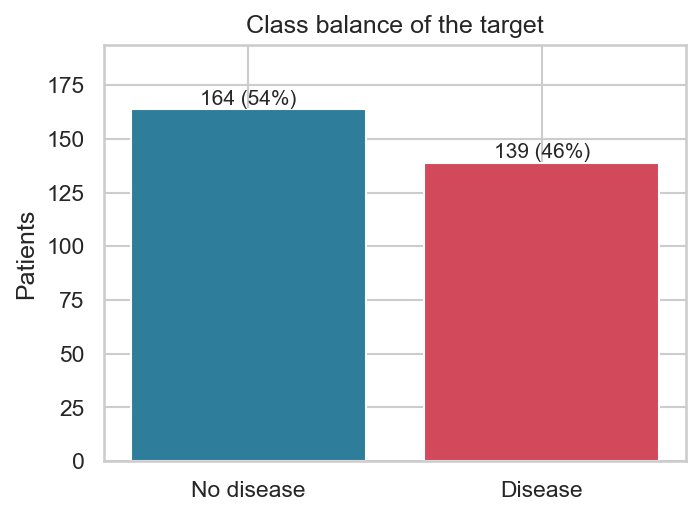

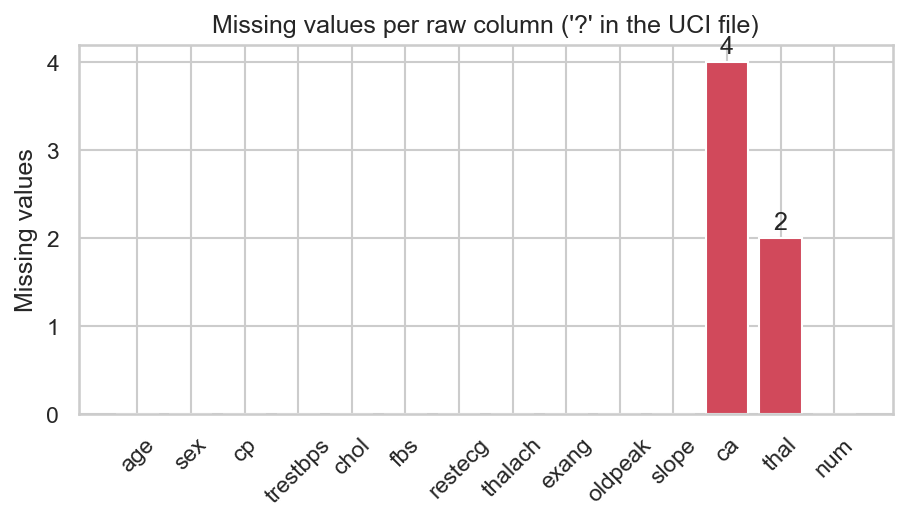

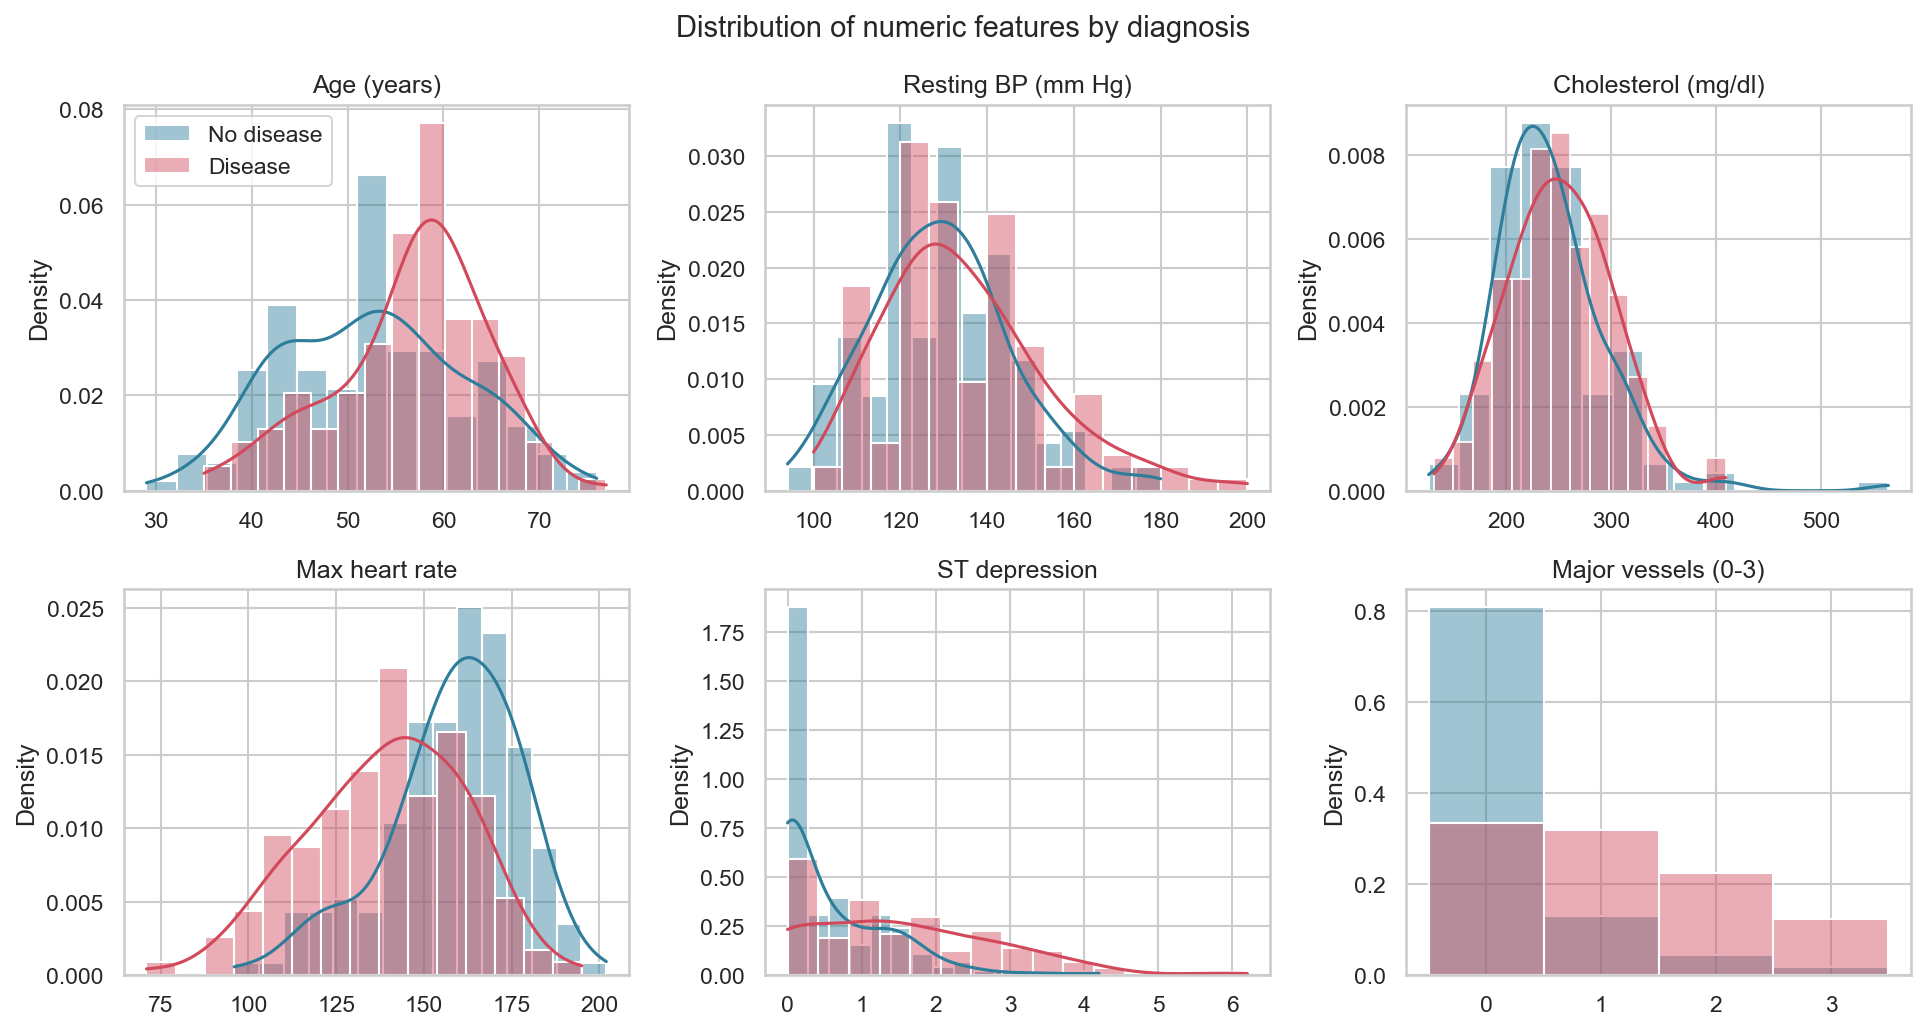

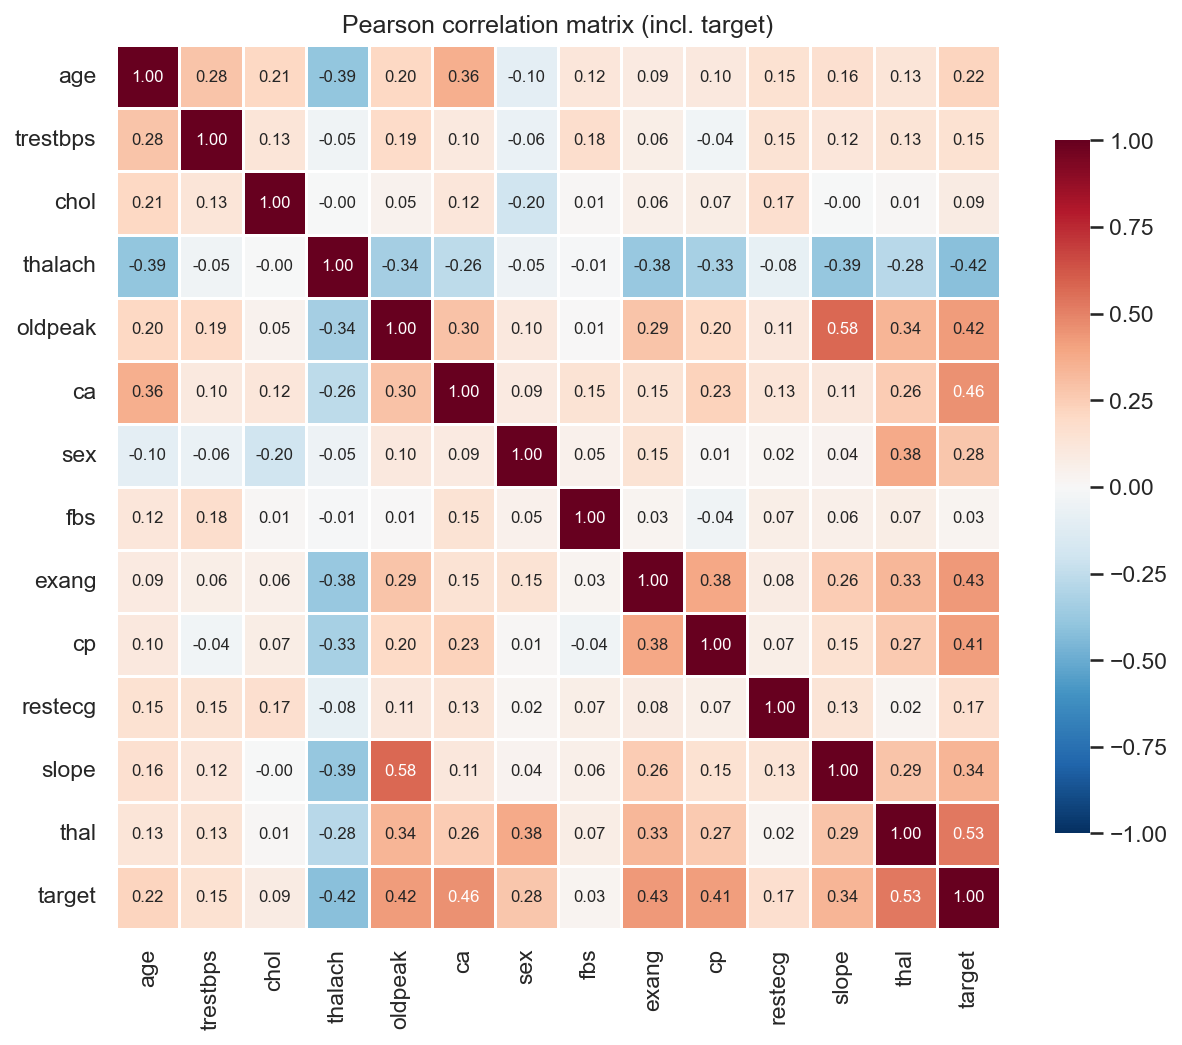

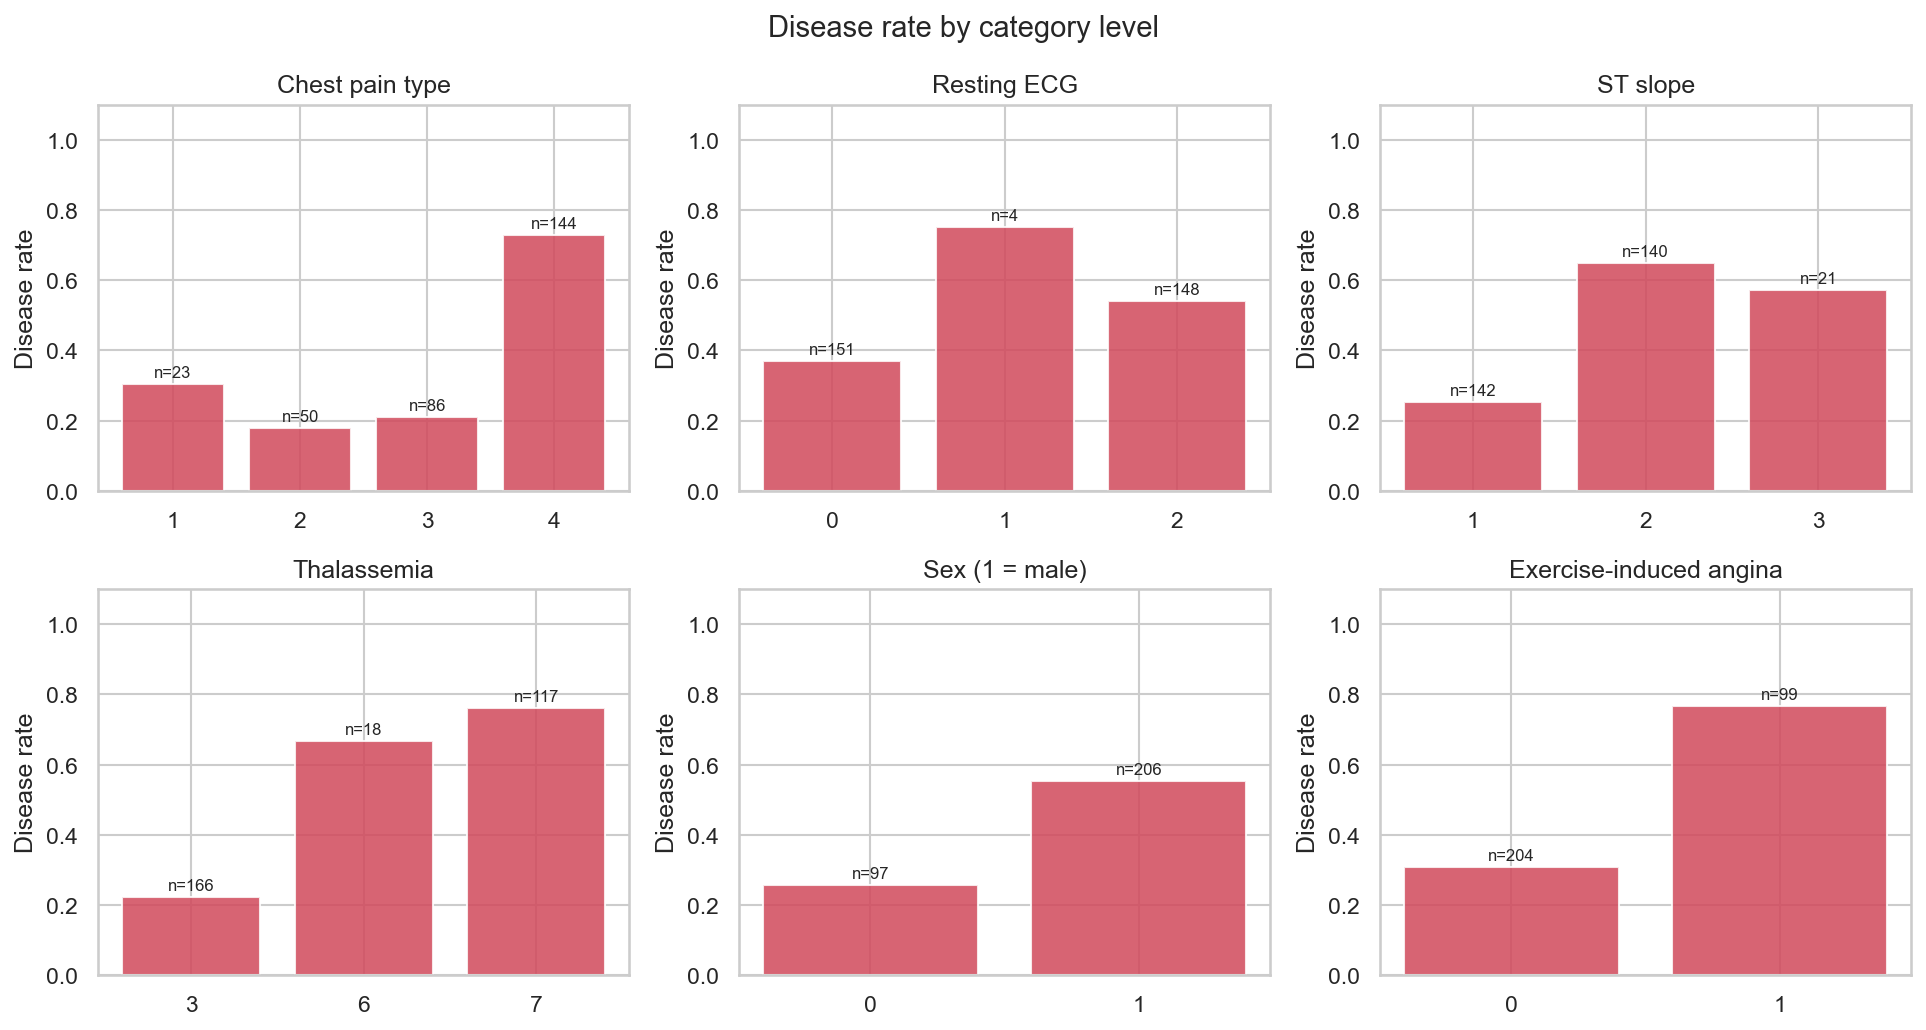

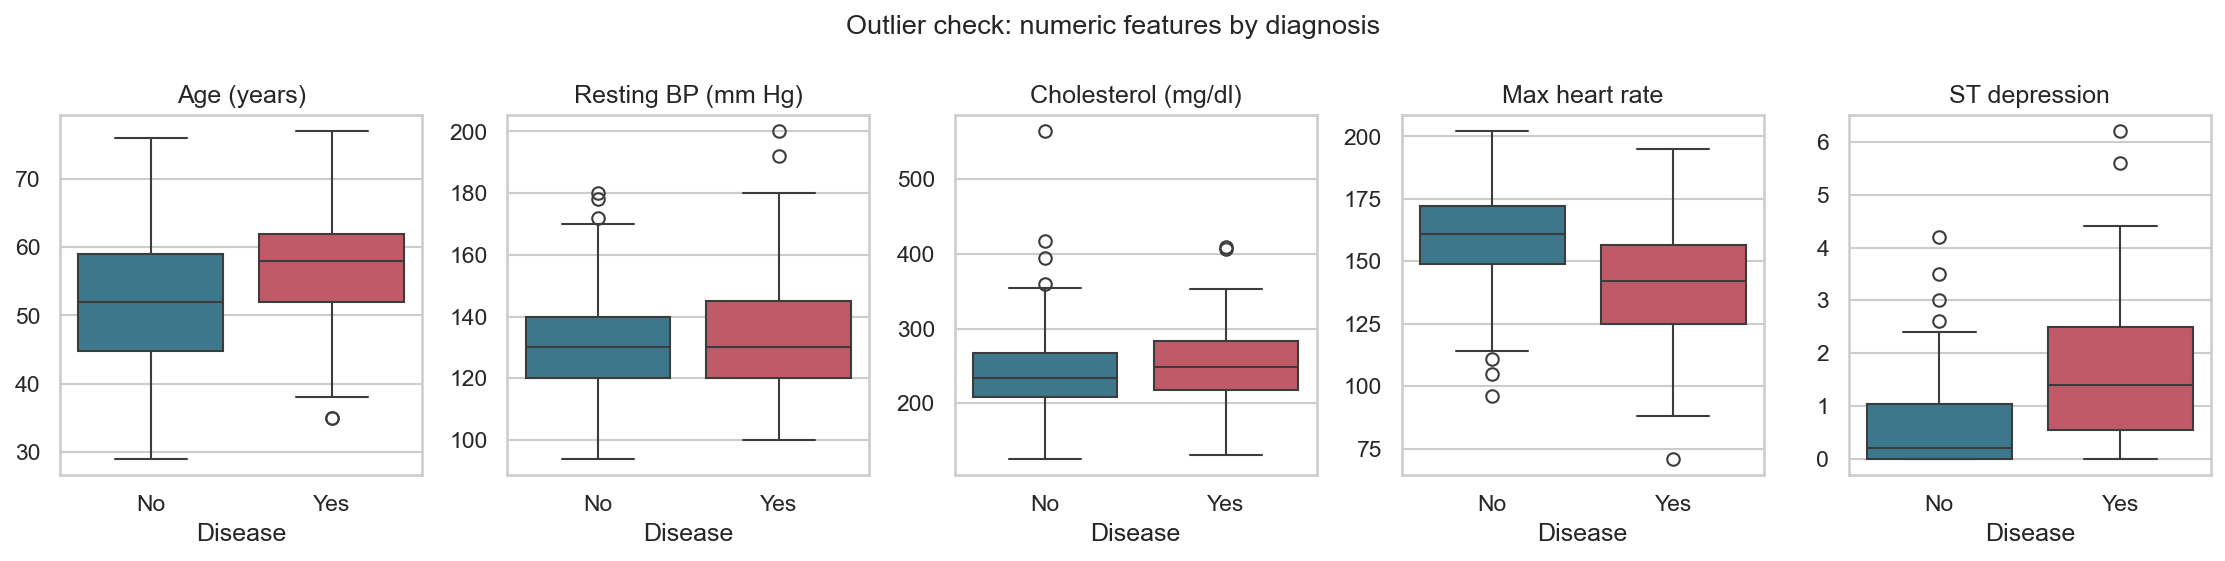

In [7]:
from IPython.display import Image, display
from heart import eda
paths = eda.run_all()
for p in paths:
    display(Image(filename=str(p), width=820))

## 5. Findings that shaped the modelling
* **Balanced target** (54% / 46%): accuracy is meaningful, but ROC-AUC is used as the primary selection metric because it is threshold-free; recall is reported because a missed disease case (false negative) is the costliest error.
* **Strongest signals**: `thal`, `ca`, `exang`, `oldpeak`, `cp` (positive) and `thalach` (negative), consistent with clinical knowledge.
* `chol` and `fbs` are weakly related to the target on their own; they are kept and left to regularisation / tree splits.
* `cp`, `restecg`, `slope`, `thal` are **nominal codes** (e.g. thal = 3/6/7), so they are one-hot encoded rather than treated as numbers.
* Numeric features are on very different scales (oldpeak 0–6 vs chol 126–564) → standardise for logistic regression; trees use raw values.
* A few high cholesterol / blood-pressure values are plausible clinically, so they are kept (validity ranges only remove impossible values).